In [17]:
import cartopy.crs as ccrs
import cartopy.feature as cf
projection = ccrs.Mercator()
crs = ccrs.PlateCarree()


import matplotlib.colors as mcolors
from utils.connected_components import connected_components_bursts
from seasonal_burst.exhaustive_search import exhaustive_search
from seasonal_burst.spatial_search import process_grid

import copy
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import HTML
import matplotlib.animation as animation
import warnings, os
import utils_notebook as ub

import matplotlib.patches as mpatches
from matplotlib.lines import Line2D


In [18]:
threshold = 3
grid_data_path="../../Data/SST/medi_1960_2021_processed_focused.nc"
parameter="sst"
n_jobs = 8
minimum_length = 1
maximum_length = 365
absolute_threshold = True
animate = False
export = True
filename_html="example_grid"
print("\033[1m"+"Parameters: "+ "\033[0m")
print(f" - threshold = {threshold}")
print(f" - grid_data_path = \"{grid_data_path}\"")
print(f" - parameter = {parameter}")
print(f" - n_jobs = {n_jobs}")
print(f" - animate = {animate}")
print(f" - export = {export}")
print(f" - filename_html = \"{filename_html}\"")

Parameters: 
 - threshold = 3
 - grid_data_path = "../../Data/SST/medi_1960_2021_processed_focused.nc"
 - parameter = sst
 - n_jobs = 8
 - animate = False
 - export = True
 - filename_html = "example_grid"


In [19]:
ds = xr.open_dataset(grid_data_path)[parameter]
time = ds.time
ts_date = pd.DatetimeIndex(time.values)
len_year = 365
n_year = len(ds.time) // len_year
lat = ds.lat.size
lon = ds.lon.size
lon_min = ds.lon.min().values
lon_max = ds.lon.max().values
lat_min = ds.lat.min().values
lat_max = ds.lat.max().values
values = ds.values.astype(np.float64)
first_year = ts_date[0].year
last_year = ts_date[-1].year
years = range(first_year, last_year+1)


values = ds.values[0,:,:]
valid_coordinates = [(i,j) for i in range(lat) for j in range(lon) if not np.isnan(values[i,j])]

In [20]:
%%time
grid_burst = process_grid(
    ds,
    valid_coordinates,
    threshold,
    n_year,
    len_year,
    minimum_length,
    maximum_length,
    exhaustive_search,
    n_jobs)

CPU times: user 40 s, sys: 4.16 s, total: 44.2 s
Wall time: 1min 23s


### Number of burst (after merging) per series

In [21]:
grid_count, grid_count_hot, grid_count_cold, grid_count_days_hot, grid_count_days_cold, coords = ub.compute_grid_counts(grid_burst, lat, lon, ds.values)

In [22]:
for i in range(lat):
    for j in range(lon):
        if grid_burst[i,j] == None:
            grid_burst[i,j] = []

### Connected Components

In [23]:
def filter_list_burst(bursts, sign, start, end):
    new_list = []
    for burst in bursts:
        s, e, z = burst
        if z == sign and s >= start and e <= end:
            new_list.append(burst)
    return new_list

In [26]:
def show_connected_components(cc_list, valid_coordinates, n_year, ts_date, lat, lon, grid_burst,
                              lon_min, lon_max, lat_min, lat_max):

    plt.figure(figsize=(16, 5))
    projection = ccrs.Mercator()
    crs = ccrs.PlateCarree()
    ax = plt.axes(projection=projection)

    # Loop over each connected component
    for idx, cc in enumerate(cc_list, start=1):
        # Create a binary mask for the current connected component.
        # 1 inside the component, 0 elsewhere.
        mask = np.zeros((lat, lon))
        for (i, j, burst_id) in cc:
            mask[i, j] = 1

        mask = np.flipud(mask)
        # Use contourf to fill the region with a semi-transparent color.
        # Levels [0.5, 1.5] ensure that only the region with value 1 is filled.
        ax.contourf(mask, levels=[0.5, 1.5], colors="blue", alpha=0.33,
                    extent=[lon_min, lon_max, lat_min, lat_max],
                    transform=ccrs.PlateCarree())

        # Optionally, overlay an outline of the component.
        ax.contour(mask, levels=[0.5], colors="darkblue", linewidths=1.5,
                   extent=[lon_min, lon_max, lat_min, lat_max],
                   transform=ccrs.PlateCarree())

    # Coastlines and borders
    ax.coastlines(resolution='50m', linewidth=1.5)
    ax.add_feature(cf.BORDERS, linestyle=':', linewidth=1.2)
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=crs)

    contour_patch = mpatches.Patch(facecolor='blue', edgecolor="black", alpha=0.5, label='Cluster Contour')
    ax.legend(handles=[contour_patch], loc='lower left')#, bbox_to_anchor=(0.5, 1.11), fancybox=True)

    plt.tight_layout()
    plt.savefig("cold_clusters.pdf", format="pdf", bbox_inches='tight')
    plt.show()

In [47]:
def grid_length(cc):
    coords = []
    for (i, j, _) in cc:
        if not (i,j) in coords:
            coords.append((i,j))
    return len(coords)
    
grid_burst_f = np.copy(grid_burst)
for i in range(lat):
    for j in range(lon):
        if len(grid_burst[i,j]) > 0:
            grid_burst_f[i,j] = filter_list_burst(grid_burst[i,j], -1, 10*365, 30*365)
        else: 
            grid_burst_f[i,j] = []

ccs = connected_components_bursts(grid_burst_f, 1)
ccs = [cc for cc in ccs if grid_length(cc) >= 200]
ccs.sort(key=len)
ccs.reverse()
print(f"In total there are {len(ccs)} connected component(s)") 

In total there are 7 connected component(s)


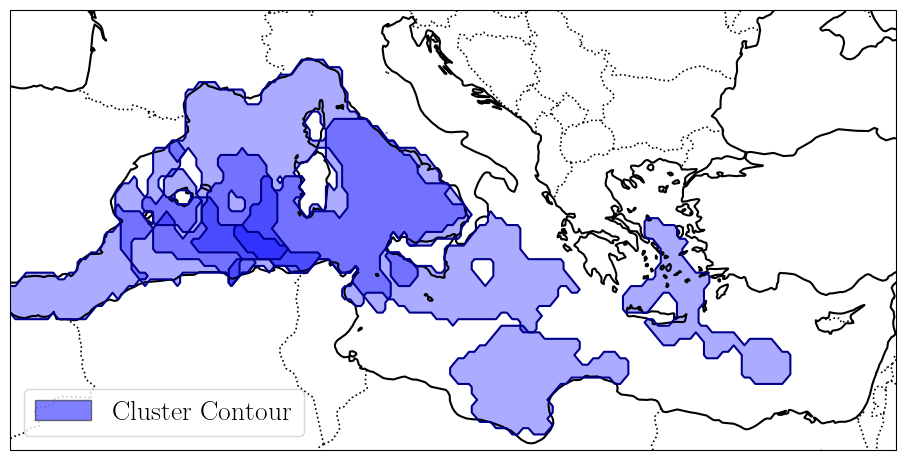

In [49]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",  
    "font.serif": ["Latin Modern Roman"],
})
plt.rcParams['font.size'] = 20

show_connected_components(ccs,valid_coordinates, n_year, ts_date, lat, lon, grid_burst, lon_min, lon_max, lat_min, lat_max)